# RQ4: V2 Advanced Combined Classification (PCA + Rigorous CV)

This notebook pushes classification performance by applying advanced models (Gradient Boosting, Random Forest, ElasticNet), dynamically tuning the number of PCA components, utilizing Stacking Ensembles, and rigorously comparing Train vs Test metrics to monitor overfitting. Data leakage is strictly prevented by embedding ComBat harmonization inside the CV folds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Advanced Classifiers
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, StackingClassifier
from sklearn.naive_bayes import GaussianNB

# Metrics
from sklearn.metrics import (accuracy_score, recall_score, precision_score, 
                             f1_score, roc_auc_score, roc_curve, 
                             precision_recall_curve, average_precision_score, 
                             confusion_matrix)

# pip install neuroCombat
try:
    from neuroCombat import neuroCombat, neuroCombatFromTraining
except ImportError:
    print("WARNING: neuroCombat not installed. Please run `pip install neuroCombat`.")

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
RNG = 42
np.random.seed(RNG)

print('Setup complete.')

Setup complete.


## 1. Data Loading and Stratified Splitting

In [2]:
# Load datasets
df_clean = pd.read_csv('../dataset/abide_solution_A.csv')
df_pheno = pd.read_csv('../Phenotypic_V1_0b_preprocessed1.csv')

# Cortical thickness columns (68 regions: 34 lh + 34 rh)
THICKNESS_COLS = sorted([c for c in df_clean.columns if c.startswith(('lh_', 'rh_'))])

# Ensure metadata columns are present
for col in ['SITE_ID', 'AGE_AT_SCAN', 'SEX', 'DX_GROUP']:
    if col not in df_clean.columns:
        df_clean = df_clean.merge(df_pheno[['SUB_ID', col]], on='SUB_ID', how='left')

# Drop subjects with missing values
df_clean = df_clean.dropna(subset=THICKNESS_COLS + ['SITE_ID', 'AGE_AT_SCAN', 'SEX', 'DX_GROUP']).reset_index(drop=True)

# Re-encode diagnosis: 1 = ASD, 0 = Control
y_all = (df_clean['DX_GROUP'] == 1).astype(int)
X_all = df_clean[THICKNESS_COLS].copy()
sites_all = df_clean['SITE_ID'].astype(str).copy()
age_all = df_clean['AGE_AT_SCAN'].copy()
sex_all = df_clean['SEX'].astype(str).copy()

# Hold-out split — strictly stratified by diagnosis
idx = np.arange(len(df_clean))
idx_tr, idx_te = train_test_split(idx, test_size=0.20, stratify=y_all, random_state=RNG)

def take(s, idx_): return s.iloc[idx_].reset_index(drop=True)

X_train, X_test = take(X_all, idx_tr), take(X_all, idx_te)
y_train, y_test = take(y_all, idx_tr), take(y_all, idx_te)
sites_train, sites_test = take(sites_all, idx_tr), take(sites_all, idx_te)
age_train, age_test = take(age_all, idx_tr), take(age_all, idx_te)
sex_train, sex_test = take(sex_all, idx_tr), take(sex_all, idx_te)

print(f'Train N = {len(X_train)} | Test N = {len(X_test)}')

Train N = 821 | Test N = 206


## 2. Rigorous In-Fold Preprocessing Framework
We define a custom grid search loop. To prevent data leakage, **ComBat and PCA** are fitted strictly on the training folds and applied to the validation folds. We also track Train AUC to explicitly monitor overfitting.

In [3]:
def fit_combat_train(X_train_df, sites_train, age_train, sex_train):
    data_T = X_train_df.T.values
    covars = pd.DataFrame({
        'SITE_ID': sites_train.reset_index(drop=True).astype(str).values,
        'AGE':     age_train.reset_index(drop=True).values,
        'SEX':     sex_train.reset_index(drop=True).astype(str).values,
    })
    result = neuroCombat(
        dat=data_T, covars=covars, batch_col='SITE_ID',
        categorical_cols=['SEX'], continuous_cols=['AGE']
    )
    X_harm = pd.DataFrame(result['data'].T, columns=X_train_df.columns, index=X_train_df.index)
    return X_harm, result['estimates']

def apply_combat_test(X_test_df, sites_test, estimates):
    data_T = X_test_df.T.values
    result = neuroCombatFromTraining(
        dat=data_T, batch=sites_test.reset_index(drop=True).astype(str).values, estimates=estimates
    )
    X_harm = pd.DataFrame(result['data'].T, columns=X_test_df.columns, index=X_test_df.index)
    return X_harm

def evaluate_pipeline(classifier, params, X, y, sites, age, sex, n_components, n_splits=5):
    '''Evaluates a classifier using ComBat -> Scaler -> PCA inside the CV fold. Returns train and val AUCs.'''
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RNG)
    val_aucs, train_aucs = [], []
    
    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
        X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
        y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]
        s_tr, s_va = sites.iloc[tr_idx], sites.iloc[va_idx]
        a_tr, a_va = age.iloc[tr_idx], age.iloc[va_idx]
        x_tr, x_va = sex.iloc[tr_idx], sex.iloc[va_idx]

        # 1. ComBat
        X_tr_h, est = fit_combat_train(X_tr, s_tr, a_tr, x_tr)
        X_va_h = apply_combat_test(X_va, s_va, est)

        # 2. Scaler
        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_tr_h)
        X_va_s = scaler.transform(X_va_h)
        
        # 3. Dynamic PCA
        pca = PCA(n_components=n_components, random_state=RNG)
        X_tr_pca = pca.fit_transform(X_tr_s)
        X_va_pca = pca.transform(X_va_s)

        # 4. Model Training
        clf = clone(classifier).set_params(**params)
        clf.fit(X_tr_pca, y_tr)
        
        # 5. Evaluate (using proba if available)
        if hasattr(clf, 'predict_proba'):
            proba_va = clf.predict_proba(X_va_pca)[:, 1]
            proba_tr = clf.predict_proba(X_tr_pca)[:, 1]
        else:
            proba_va = clf.decision_function(X_va_pca)
            proba_tr = clf.decision_function(X_tr_pca)
            
        val_aucs.append(roc_auc_score(y_va, proba_va))
        train_aucs.append(roc_auc_score(y_tr, proba_tr))
        
    return np.mean(val_aucs), np.mean(train_aucs)

## 3. Dynamic Grid Search
We search over both the model's hyperparameters AND the number of PCA components ($k$). This allows complex models to use more components, while linear models might prefer fewer.

In [4]:
from itertools import product

def advanced_grid_search(classifier_class, param_grid, pca_ks=[10, 15, 20, 30]):
    keys = list(param_grid.keys())
    combos = list(product(*[param_grid[k] for k in keys]))
    
    best_val_auc = -1
    best_train_auc = -1
    best_params = None
    best_k = None
    
    total_iters = len(combos) * len(pca_ks)
    print(f"Running {total_iters} configurations...")
    
    for k in pca_ks:
        for combo in combos:
            params = dict(zip(keys, combo))
            val_auc, train_auc = evaluate_pipeline(
                classifier_class(), params, X_train, y_train, 
                sites_train, age_train, sex_train, n_components=k
            )
            
            if val_auc > best_val_auc:
                best_val_auc = val_auc
                best_train_auc = train_auc
                best_params = params
                best_k = k
                
    return best_params, best_k, best_val_auc, best_train_auc

# Dictionary to store the optimal configuration for each algorithm
best_configs = {}

In [5]:
# 1. Logistic Regression (ElasticNet penalty for feature selection)
lr_grid = {
    'penalty': ['elasticnet'],
    'l1_ratio': [0.1, 0.5, 0.9],
    'C': [0.01, 0.1, 1.0, 10.0],
    'solver': ['saga'],
    'class_weight': ['balanced'],
    'max_iter': [2000],
    'random_state': [RNG]
}
print("Tuning Logistic Regression...")
b_params, b_k, b_val, b_tr = advanced_grid_search(LogisticRegression, lr_grid, pca_ks=[10, 15, 20, 30])
best_configs['Logistic Regression'] = {'params': b_params, 'k': b_k, 'val_auc': b_val, 'train_auc': b_tr}
print(f"Best: k={b_k}, Params: {b_params}\nVal AUC: {b_val:.3f} (Train AUC: {b_tr:.3f})")

Tuning Logistic Regression...
Running 48 configurations...
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[ne

In [6]:
# 2. Random Forest
rf_grid = {
    'n_estimators': [100, 300],
    'max_depth': [3, 5, 10],
    'min_samples_leaf': [2, 5, 10],
    'class_weight': ['balanced'],
    'random_state': [RNG]
}
print("\nTuning Random Forest...")
b_params, b_k, b_val, b_tr = advanced_grid_search(RandomForestClassifier, rf_grid, pca_ks=[10, 15, 20, 30, 40])
best_configs['Random Forest'] = {'params': b_params, 'k': b_k, 'val_auc': b_val, 'train_auc': b_tr}
print(f"Best: k={b_k}, Params: {b_params}\nVal AUC: {b_val:.3f} (Train AUC: {b_tr:.3f})")


Tuning Random Forest...
Running 90 configurations...
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCo

In [7]:
# 3. HistGradientBoosting (LightGBM equivalent)
hgb_grid = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_iter': [100, 200],
    'max_depth': [3, 5],
    'min_samples_leaf': [10, 20],
    'l2_regularization': [0.0, 1.0, 5.0],
    'random_state': [RNG]
}
print("\nTuning HistGradientBoosting...")
b_params, b_k, b_val, b_tr = advanced_grid_search(HistGradientBoostingClassifier, hgb_grid, pca_ks=[10, 15, 20, 30])
best_configs['Gradient Boosting'] = {'params': b_params, 'k': b_k, 'val_auc': b_val, 'train_auc': b_tr}
print(f"Best: k={b_k}, Params: {b_params}\nVal AUC: {b_val:.3f} (Train AUC: {b_tr:.3f})")


Tuning HistGradientBoosting...
Running 288 configurations...
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors


In [8]:
# 4. SVM (RBF)
svm_grid = {
    'kernel': ['rbf'],
    'C': [0.1, 1.0, 10.0],
    'gamma': ['scale', 'auto', 0.01],
    'class_weight': ['balanced'],
    'probability': [True],
    'random_state': [RNG]
}
print("\nTuning SVM...")
b_params, b_k, b_val, b_tr = advanced_grid_search(SVC, svm_grid, pca_ks=[10, 15, 20, 30])
best_configs['SVM'] = {'params': b_params, 'k': b_k, 'val_auc': b_val, 'train_auc': b_tr}
print(f"Best: k={b_k}, Params: {b_params}\nVal AUC: {b_val:.3f} (Train AUC: {b_tr:.3f})")


Tuning SVM...
Running 36 configurations...
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Find

## 4. Final Evaluation & Advanced Stacking Ensemble on Hold-Out Test Set
We now train the optimized models on the **full training set** and evaluate them strictly on the **sealed 20% test set**. We also build a **Stacking Classifier**, which learns how to optimally combine the predictions of the base models.

In [9]:
# 1. Full Train ComBat & Scaler
X_train_h, est_full = fit_combat_train(X_train, sites_train, age_train, sex_train)
X_test_h = apply_combat_test(X_test, sites_test, est_full)

scaler_full = StandardScaler()
X_train_hs = scaler_full.fit_transform(X_train_h)
X_test_hs = scaler_full.transform(X_test_h)

# 2. Re-instantiate optimized models
final_models = {}
for name in ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'SVM']:
    cfg = best_configs[name]
    
    # We must fit PCA specifically for this model's optimal k
    pca = PCA(n_components=cfg['k'], random_state=RNG)
    X_tr_pca = pca.fit_transform(X_train_hs)
    X_te_pca = pca.transform(X_test_hs)
    
    # Map model name to class
    if name == 'Logistic Regression': clf = LogisticRegression(**cfg['params'])
    elif name == 'Random Forest': clf = RandomForestClassifier(**cfg['params'])
    elif name == 'Gradient Boosting': clf = HistGradientBoostingClassifier(**cfg['params'])
    elif name == 'SVM': clf = SVC(**cfg['params'])
    
    clf.fit(X_tr_pca, y_train)
    final_models[name] = {
        'clf': clf,
        'pca': pca,
        'k': cfg['k'],
        'X_tr_pca': X_tr_pca,
        'X_te_pca': X_te_pca
    }

# 3. Build Stacking Ensemble (To simplify, we'll force the stacker to use a common PCA k, e.g., k=20)
print("Building Stacking Ensemble (PCA k=20)...")
stack_pca = PCA(n_components=20, random_state=RNG)
X_tr_stack = stack_pca.fit_transform(X_train_hs)
X_te_stack = stack_pca.transform(X_test_hs)

estimators = [
    ('lr', LogisticRegression(**best_configs['Logistic Regression']['params'])),
    ('rf', RandomForestClassifier(**best_configs['Random Forest']['params'])),
    ('gb', HistGradientBoostingClassifier(**best_configs['Gradient Boosting']['params'])),
    ('svm', SVC(**best_configs['SVM']['params']))
]
stacker = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(), cv=5)
stacker.fit(X_tr_stack, y_train)
final_models['Stacking Ensemble'] = {
    'clf': stacker, 'pca': stack_pca, 'k': 20, 
    'X_tr_pca': X_tr_stack, 'X_te_pca': X_te_stack
}

# 4. Generate Predictions on Test Set
test_results = []
test_probas = {}

for name, meta in final_models.items():
    clf = meta['clf']
    X_te_pca = meta['X_te_pca']
    
    y_pred = clf.predict(X_te_pca)
    y_proba = clf.predict_proba(X_te_pca)[:, 1] if hasattr(clf, 'predict_proba') else clf.decision_function(X_te_pca)
    
    test_probas[name] = y_proba
    
    test_results.append({
        'Model': name,
        'PCA_k': meta['k'],
        'Test AUC': roc_auc_score(y_test, y_proba),
        'Test Acc': accuracy_score(y_test, y_pred),
        'Test Precision': precision_score(y_test, y_pred, zero_division=0),
        'Test Recall': recall_score(y_test, y_pred, zero_division=0),
        'Test F1': f1_score(y_test, y_pred, zero_division=0),
        'CV Val AUC': best_configs[name]['val_auc'] if name in best_configs else np.nan,
        'CV Train AUC': best_configs[name]['train_auc'] if name in best_configs else np.nan
    })

results_df = pd.DataFrame(test_results).sort_values('Test AUC', ascending=False)


[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

Building Stacking Ensemble (PCA k=20)...


## 5. Review Results & Comparison
A comprehensive analysis of the models' performance, checking for accuracy improvements and ensuring no severe overfitting occurred.

In [10]:
# Display Metrics Table
display(results_df.round(3).set_index('Model'))

,PCA_k,Test AUC,Test Acc,Test Precision,Test Recall,Test F1,CV Val AUC,CV Train AUC
Model,,,,,,,,
Random Forest,30,0.555,0.568,0.558,0.53,0.544,0.628,0.954
Logistic Regression,30,0.554,0.515,0.500,0.49,0.495,0.593,0.667
Gradient Boosting,20,0.545,0.519,0.505,0.51,0.507,0.611,1.000
Stacking Ensemble,20,0.524,0.510,0.495,0.45,0.471,NaN,NaN
SVM,30,0.483,0.505,0.488,0.42,0.452,0.626,0.961


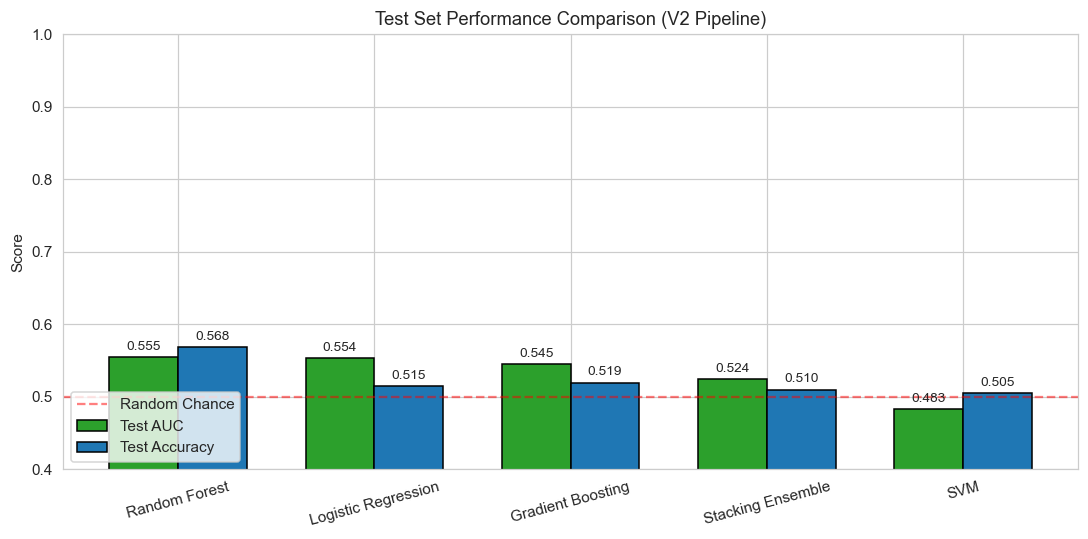

In [11]:
# 1. Bar Chart: AUC and Accuracy Comparison
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(results_df))
width = 0.35

ax.bar(x - width/2, results_df['Test AUC'], width, label='Test AUC', color='#2ca02c', edgecolor='black')
ax.bar(x + width/2, results_df['Test Acc'], width, label='Test Accuracy', color='#1f77b4', edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(results_df['Model'], rotation=15)
ax.set_ylim(0.4, 1.0)
ax.axhline(0.5, color='red', linestyle='--', alpha=0.5, label='Random Chance')
ax.set_ylabel('Score')
ax.set_title('Test Set Performance Comparison (V2 Pipeline)')
ax.legend(loc='lower left')

for i in range(len(results_df)):
    ax.text(i - width/2, results_df.iloc[i]['Test AUC'] + 0.01, f"{results_df.iloc[i]['Test AUC']:.3f}", ha='center', fontsize=9)
    ax.text(i + width/2, results_df.iloc[i]['Test Acc'] + 0.01, f"{results_df.iloc[i]['Test Acc']:.3f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

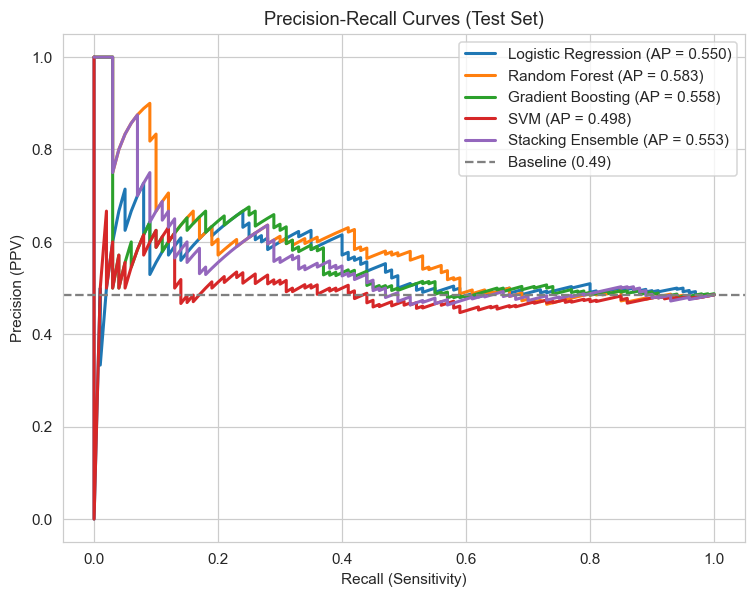

In [12]:
# 2. Precision-Recall Curves (Critical for imbalanced medical data)
fig, ax = plt.subplots(figsize=(8, 6))

for name, proba in test_probas.items():
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    ax.plot(rec, prec, lw=2, label=f'{name} (AP = {ap:.3f})')

baseline = y_test.mean()
ax.axhline(baseline, color='grey', linestyle='--', label=f'Baseline ({baseline:.2f})')
ax.set_xlabel('Recall (Sensitivity)')
ax.set_ylabel('Precision (PPV)')
ax.set_title('Precision-Recall Curves (Test Set)')
ax.legend(loc='upper right')
plt.show()

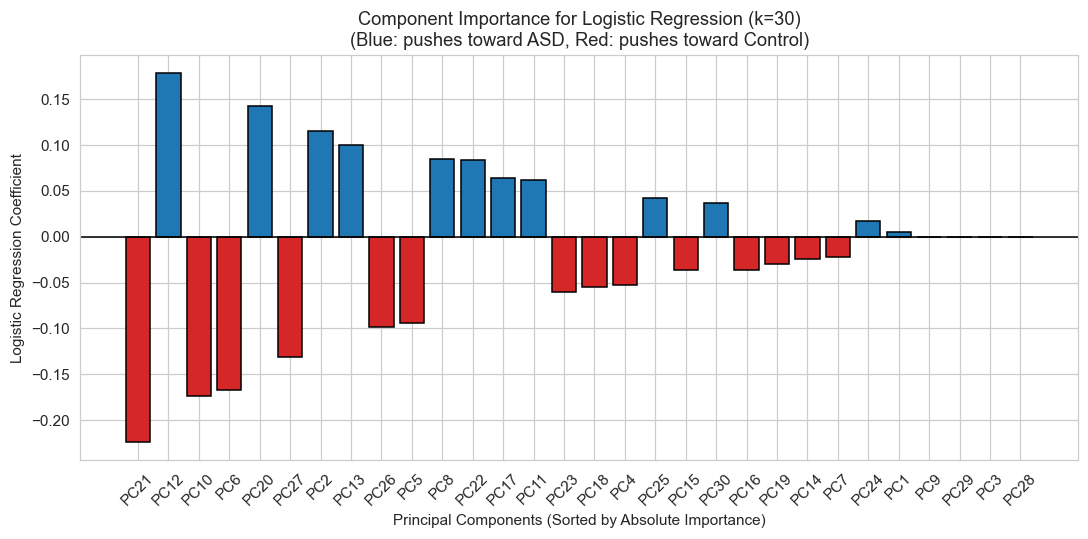

In [13]:
# 3. Model Interpretation: Logistic Regression Coefficients mapped to PCA components
lr_meta = final_models['Logistic Regression']
lr_clf = lr_meta['clf']
pca_k = lr_meta['k']

coefs = lr_clf.coef_[0]
indices = np.argsort(np.abs(coefs))[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(pca_k), coefs[indices], color=['#d62728' if c < 0 else '#1f77b4' for c in coefs[indices]], edgecolor='black')
ax.set_xticks(range(pca_k))
ax.set_xticklabels([f'PC{i+1}' for i in indices], rotation=45)
ax.set_xlabel('Principal Components (Sorted by Absolute Importance)')
ax.set_ylabel('Logistic Regression Coefficient')
ax.set_title(f'Component Importance for Logistic Regression (k={pca_k})\n(Blue: pushes toward ASD, Red: pushes toward Control)')
ax.axhline(0, color='black', linewidth=1)
plt.tight_layout()
plt.show()